# Do Pictures Pay Off? Image Posts vs. Text-Only Posts on Bluesky

**Name:** Jessica Fox  
**Date:** October 21, 2026
**Report:** Bluesky API Data Report

**Hypothesis:** On Bluesky, posts that include images receive more engagement than text-only posts from the same account.

## Additional Resources 

**I used a handful of additional resources to assist me when working on this assignment, as I felt that my understanding was lacking in quite a few areas**

1. Free Code Camp
   - https://www.freecodecamp.org/news/apis-for-beginners/
2. YouTube: I used multiple videos from different creators
   - https://www.youtube.com/playlist?list=PL-osiE80TeTsWmV9i9c58mdDCSskIFdDS
   - https://www.youtube.com/watch?v=KurDt6-lmSU
3. Claude Code
   - I have listed the points in the assignment where I used AI for extra help, but it was mainly for troubleshooting. I get impatient searching through lines of code to find my errors, but also had Claude give me some suggestions on the code
4. Grammarly AI
   - I use Grammarly's web extension to assist with the grammar and syntax of my writing

## Theoretical and Statistical Applications

**Theoretical application.** Social media feeds are competitive spaces where posts fight for a few seconds of attention. Research on visual communication suggests that images are processed faster and stand out more while scrolling, so we might expect image posts to attract more likes, reposts, and replies. However, Bluesky has a reputation as a text-forward, conversation-driven platform (similar to early Twitter), so images may matter less here than on platforms like Instagram. Testing this hypothesis tells us something about what kind of content Bluesky's audience rewards.

**Statistical application.** The unit of analysis is the individual post, but posts are grouped within accounts. Popular accounts get more engagement on everything, so comparing image posts from a large account with text posts from a small account would be misleading. Instead, this report makes a within-account comparison: for each account, I calculate the average engagement of its image posts and of its text-only posts, then compare the two. This sets up a paired comparison that we can test later. I also scale engagement by follower count so that accounts of very different sizes can be shown on the same chart.

This design can show an association, not causation: account owners choose when to add images, and they may save images for posts they already expect to do well.

## Variables
**Claude Code helped me format this section into a table, since I didn't like how messy I had made it look**

| Variable | Description | Source endpoint | Role |
|---|---|---|---|
| `post_type` | Whether a post is text-only or includes images, derived from the post's `embed` field | `getAuthorFeed` | Independent variable |
| `engagement` | Likes + reposts + replies + quotes on a post | `getAuthorFeed` | Dependent variable |
| `followers` | Number of followers the account has | `getProfile` | Used to scale engagement across accounts |
| `did` | The account's permanent unique identifier | Both | Key used to merge the DataFrames |
| `handle` | The account's human-readable name | `getProfile` | Labels for tables and charts |
| `created_at` | When each post was made | `getAuthorFeed` | Used to check the time window covered for each account |

## Data Source and Structure

The data comes from Bluesky's public AppView API (`https://public.api.bsky.app/xrpc`), which serves public data from the AT Protocol network. These endpoints do not require a login or token. All responses are JSON objects.

### Endpoint 1: app.bsky.actor.getProfile
- **Parameters:** actor, a single handle or DID.
- **Response:** one profile object including did, handle, displayName, followersCount, followsCount, postsCount, and createdAt.
- **Why it's suitable:** it provides each account's follower count, which I need to put accounts of different sizes on a comparable scale. The did field gives a reliable key for merging because, unlike a handle, it never changes.

### Endpoint 2: app.bsky.feed.getAuthorFeed
- **Parameters:** actor (one account), limit (up to 100 posts per request), and filter (I use posts_no_replies so replies in other people's threads don't get mixed in with standalone posts).
- **Response:** an object with a feed list. Each item contains a post object with author, uri, record (the text and createdAt), an optional embed, and the counts likeCount, repostCount, replyCount, and quoteCount. If the item is a repost of someone else's content, it also has a reason field.
- **Why it's suitable:** This is the only place to get per-post engagement counts together with information about what the post contained. The embed field's $type tells me whether a post has images (AI helped me discover that).

### Reliability
The engagement counts come directly from Bluesky's own index rather than from estimates or scraping, and every post has a timestamp and a permanent identifier. The embed type is a structured field, so classifying posts doesn't require guessing from the text.

### Unreliability, limitations, and caveats
- **Snapshots, not final values.** Counts are recorded at the moment of the request. A post from an hour ago has had far less time to collect likes than a post from last week, which biases recent posts downward.
- **No view counts.** The API doesn't report impressions, so I can't calculate a true engagement rate. Dividing by followers is a stand-in, but many people see posts through custom feeds and search without following the account.
- **Only recent posts.** I collect each account's 100 most recent posts. For an account that posts constantly, that may be one day; for an occasional poster, it may be months. The accounts are not observed over the same time period.
- **Follower counts can be inflated** by inactive or bot accounts.
- **Hidden factors.** Topic, time of day, and breaking news all affect engagement and aren't captured here.
- **Non-random sample.** I chose the accounts myself, so the results can't be generalized to all of Bluesky.

In [1]:
#Loading the tools that I'll need
import requests
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://public.api.bsky.app/xrpc"

## Choosing the Sample

I selected a sample of well-known accounts from different categories (news organizations, Bluesky staff, and public figures) with a wide range of follower counts. I chose accounts likely to post both images and text, since an account that never posts either type can't be used in a within-account comparison.

In [2]:
#The accounts I want to use
accounts = [
    "bsky.app",
    "jay.bsky.team",
    "pfrazee.com",
    "nytimes.com",
    "npr.org",
    "theonion.com",
    "washingtonpost.com",
    "georgetakei.bsky.social",
]

print("Number of accounts in sample:", len(accounts))

Number of accounts in sample: 8


## Collecting Profile Data

First I make a single test request to confirm the endpoint works and to look at which keys the response contains.

In [3]:
#Testing the request
response = requests.get(
    BASE + "/app.bsky.actor.getProfile",
    params={"actor": accounts[0]}, timeout=15
)
print(response.status_code)

response.raise_for_status()
data = response.json()
print(data.keys())

200
dict_keys(['did', 'handle', 'displayName', 'avatar', 'associated', 'labels', 'createdAt', 'verification', 'status', 'description', 'indexedAt', 'banner', 'followersCount', 'followsCount', 'postsCount', 'pinnedPost'])


Now I loop through every account. For each one, I print the status code, use raise_for_status() to stop if the request failed, and append a dictionary of the fields I need to the profiles list. I use .get() with a default of 0 so a missing count doesn't cause an error. Finally, the list of dictionaries becomes a DataFrame.

In [4]:
profiles = []

for account in accounts:
    response = requests.get(
        BASE + "/app.bsky.actor.getProfile",
        params={"actor": account}, timeout=15
    )
    print(account, response.status_code)
    response.raise_for_status()
    data = response.json()

    profiles.append({
        "did": data["did"],
        "handle": data["handle"],
        "followers": data.get("followersCount", 0),
        "following": data.get("followsCount", 0),
        "total_posts": data.get("postsCount", 0)
    })

profiles_df = pd.DataFrame(profiles)
display(profiles_df)

bsky.app 200
jay.bsky.team 200
pfrazee.com 200
nytimes.com 200
npr.org 200
theonion.com 200
washingtonpost.com 200
georgetakei.bsky.social 200


,did,handle,followers,following,total_posts
0,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35333800,23,886
1,did:plc:oky5czdrnfjpqslsw2a5iclo,jay.bsky.team,594470,3994,4185
2,did:plc:ragtjsm2j2vknwkz3zp4oxrd,pfrazee.com,309418,710,40289
3,did:plc:eclio37ymobqex2ncko63h4r,nytimes.com,1352909,123,44566
4,did:plc:ln72v57ivz2g46uqf4xxqiuh,npr.org,1013230,238,19312
5,did:plc:a4pqq234yw7fqbddawjo7y35,theonion.com,1359114,5,8844
6,did:plc:k5nskatzhyxersjilvtnz4lh,washingtonpost.com,874254,149,26363
7,did:plc:y4zs4cabaezzwx3bz2e5nnj2,georgetakei.bsky.social,1323330,422,16421


## Collecting Posts from Each Account

Testing request to check the structure of the feed response before writing the full loop.

In [5]:
feed_url = BASE + "/app.bsky.feed.getAuthorFeed"
response = requests.get(
    feed_url,
    params={"actor": profiles_df.loc[0, "did"],
            "limit": 100, "filter": "posts_no_replies"},
    timeout=15
)
response.raise_for_status()
sample = response.json()
print(sample.keys())
print(sample["feed"][0].keys())
print(sample["feed"][0]["post"].keys())

dict_keys(['feed', 'cursor'])
dict_keys(['post', 'reason', 'opThreadPostIndex', 'opThreadPostCount'])
dict_keys(['uri', 'cid', 'author', 'record', 'embed', 'bookmarkCount', 'replyCount', 'repostCount', 'likeCount', 'quoteCount', 'indexedAt', 'labels'])


For each account, I request its 100 most recent posts and use a list comprehension to build one dictionary per post. Two data-cleaning decisions happen inside the list comprehension:

1. **Removing reposts.** The author feed includes posts the account reposted from other people. Those posts' likes belong to someone else, so I skip any item with a reason field and double-check that the post's author matches the account (Claude suggested this while I was troubleshooting an issue). Pinned posts also have a reason field, so I skip each account's pinned post as well.
2. **Recording the embed type.** If a post has no embed, I record "none". Otherwise, I record the embed's $type, which I'll use in the next step to classify the post.

In [6]:
post_frames = []

for profile in profiles:
    resp = requests.get(
        feed_url,
        params={"actor": profile["did"], "limit": 100,
                "filter": "posts_no_replies"},
        timeout=15
    )
    resp.raise_for_status()
    feed = resp.json().get("feed", [])

    rows = [
        {
            "did": item["post"]["author"]["did"],
            "uri": item["post"]["uri"],
            "url": f"https://bsky.app/profile/{item['post']['author']['did']}/post/{item['post']['uri'].split('/')[-1]}",
            "text": item["post"]["record"].get("text", ""),
            "embed_type": item["post"].get("embed", {}).get("$type", "none"),
            "likes": item["post"].get("likeCount", 0),
            "reposts": item["post"].get("repostCount", 0),
            "replies": item["post"].get("replyCount", 0),
            "quotes": item["post"].get("quoteCount", 0),
            "created_at": item["post"]["record"].get("createdAt"),
        }
        #Skipping reposts
        for item in feed
        if "reason" not in item
        and item["post"]["author"]["did"] == profile["did"]
    ]

    #Shows me what posts were kept after skipping the reposts
    print(profile["handle"], "-", len(rows), "posts kept")
    post_frames.append(pd.DataFrame(rows))

posts_df = pd.concat(post_frames, ignore_index=True)
display(posts_df.head())

bsky.app - 63 posts kept
jay.bsky.team - 50 posts kept
pfrazee.com - 43 posts kept
nytimes.com - 88 posts kept
npr.org - 100 posts kept
theonion.com - 94 posts kept
washingtonpost.com - 97 posts kept
georgetakei.bsky.social - 82 posts kept


,did,uri,url,text,embed_type,likes,reposts,replies,quotes,created_at
0,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,STREAMING LIVE NOW: stream.place/niedermeyer....,app.bsky.embed.record#view,544,92,31,8,2026-10-20T16:01:12.410Z
1,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,"if you remember none pizza with left beef, it'...",app.bsky.embed.record#view,1937,226,116,59,2026-10-19T20:53:01.192Z
2,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,no kings includes billionaires who think they’...,app.bsky.embed.record#view,9138,1765,659,419,2026-10-17T21:55:13.889Z
3,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,"“Pro wrestling conversations, like sports on B...",app.bsky.embed.record#view,1054,116,114,75,2026-10-16T20:09:31.738Z
4,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,v1.135 is live!\n\nYou can now browse quote po...,app.bsky.embed.video#view,1440,205,179,80,2026-10-16T16:23:26.498Z


## Cleaning and Classifying Posts

I use a list comprehension to turn the raw embed_type into a simple post_type label: image for Bluesky's image embed, text_only for posts with no embed, and other for everything else (videos, link cards, quote posts). I also add up the four engagement counts into one engagement column and remove any duplicate posts by their unique uri.

In [7]:
#Labeling posts based on attachment
posts_df["post_type"] = [
    "image" if t == "app.bsky.embed.images#view"
    else "text_only" if t == "none"
    else "other"
    for t in posts_df["embed_type"]
]

# Add up all kinds of interaction into one engagement number per post
posts_df["engagement"] = (
    posts_df["likes"] + posts_df["reposts"]
    + posts_df["replies"] + posts_df["quotes"]
)

#Removing posts that appear more than once
posts_df = posts_df.drop_duplicates(subset="uri")

#Counting how many posts are in each category
print(posts_df["post_type"].value_counts())

post_type
other        438
image        138
text_only     41
Name: count, dtype: int64


Because my hypothesis compares only image posts with text-only posts, I drop the other category, along with columns I no longer need.

In [8]:
#Keep only posts with images or only text
posts_df = posts_df[posts_df["post_type"] != "other"]
#This function is one I learned from YouTube
posts_df = posts_df.drop(columns=["embed_type", "text"])

#Show what's remaining
print("Posts remaining:", len(posts_df))

Posts remaining: 179


## Merging Posts with Profile Data

I use pd.merge() to add each account's handle and follower count to every post, matching on did. Setting validate="many_to_one" confirms that each post matches exactly one profile.

In [9]:
combined_df = pd.merge(
    posts_df,
    profiles_df[["did", "handle", "followers"]],
    on="did", how="left", validate="many_to_one"
)
display(combined_df.head())

,did,uri,url,likes,reposts,replies,quotes,created_at,post_type,engagement,handle,followers
0,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,7666,413,235,44,2026-10-14T17:35:30.592Z,image,8358,bsky.app,35333800
1,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,1884,170,375,51,2026-09-09T17:02:28.502Z,text_only,2480,bsky.app,35333800
2,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,2360,160,117,41,2026-09-09T15:00:07.513Z,image,2678,bsky.app,35333800
3,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,1436,266,65,49,2026-09-04T16:21:11.628Z,image,1816,bsky.app,35333800
4,did:plc:z72i7hdynmk6r22z27h6tvur,at://did:plc:z72i7hdynmk6r22z27h6tvur/app.bsky...,https://bsky.app/profile/did:plc:z72i7hdynmk6r...,9624,3351,343,1615,2026-08-27T19:03:40.083Z,image,14933,bsky.app,35333800


### Checking the time window

Because each account posts at a different rate, the 100 posts I collected cover different time periods. Bluesky timestamps use a standard format (year-month-day first), so the earliest and latest posts can be found with min and max directly on the text. This is another suggestion that Claude gave me.

In [10]:
# For each account, find the date of its oldest and newest collected post,
# and count its posts, to see how much time the data covers
time_window_df = (
    combined_df.groupby(["did", "handle"], as_index=False)
    .agg(
        earliest_post=("created_at", "min"),
        latest_post=("created_at", "max"),
        posts_collected=("uri", "count"),
    )
)
display(time_window_df)

,did,handle,earliest_post,latest_post,posts_collected
0,did:plc:a4pqq234yw7fqbddawjo7y35,theonion.com,2026-10-13T18:00:25.627942047Z,2026-10-21T20:00:24.785122277Z,65
1,did:plc:eclio37ymobqex2ncko63h4r,nytimes.com,2026-10-19T00:14:17.210Z,2026-10-21T20:10:04.682319Z,20
2,did:plc:k5nskatzhyxersjilvtnz4lh,washingtonpost.com,2026-10-20T02:00:04.763417774Z,2026-10-21T19:30:07.640001231Z,10
3,did:plc:oky5czdrnfjpqslsw2a5iclo,jay.bsky.team,2026-03-29T18:55:15.012Z,2026-10-16T18:28:58.362Z,32
4,did:plc:ragtjsm2j2vknwkz3zp4oxrd,pfrazee.com,2026-09-30T23:44:29.838Z,2026-10-21T20:07:20.937Z,25
5,did:plc:y4zs4cabaezzwx3bz2e5nnj2,georgetakei.bsky.social,2026-10-16T14:28:31.745Z,2026-10-16T17:49:17.699Z,2
6,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,2026-03-19T16:26:13.953Z,2026-10-14T17:35:30.592Z,25


## Building the Comparison Dataset

To compare post types within each account, I:

1. Use groupby() and .agg() to calculate the average engagement and number of posts for each account and post type.
2. Split the result into a text-only DataFrame and an image DataFrame.
3. Merge those two back together, so each account has one row with both averages side by side.

In [11]:
# Group posts by account AND post type, then for each group calculate:
# the follower count, the average engagement, and the number of posts
summary_df = (
    combined_df.groupby(["did", "handle", "post_type"], as_index=False)
    .agg(
        followers=("followers", "first"),
        avg_engagement=("engagement", "mean"),
        n_posts=("engagement", "count"),
    )
)
display(summary_df)

,did,handle,post_type,followers,avg_engagement,n_posts
0,did:plc:a4pqq234yw7fqbddawjo7y35,theonion.com,image,1359114,1444.984615,65
1,did:plc:eclio37ymobqex2ncko63h4r,nytimes.com,image,1352909,236.150000,20
2,did:plc:k5nskatzhyxersjilvtnz4lh,washingtonpost.com,image,874254,105.400000,10
3,did:plc:oky5czdrnfjpqslsw2a5iclo,jay.bsky.team,image,594470,634.517241,29
4,did:plc:oky5czdrnfjpqslsw2a5iclo,jay.bsky.team,text_only,594470,1282.333333,3
5,did:plc:ragtjsm2j2vknwkz3zp4oxrd,pfrazee.com,image,309418,113.000000,1
6,did:plc:ragtjsm2j2vknwkz3zp4oxrd,pfrazee.com,text_only,309418,145.166667,24
7,did:plc:y4zs4cabaezzwx3bz2e5nnj2,georgetakei.bsky.social,image,1323330,2350.000000,1
8,did:plc:y4zs4cabaezzwx3bz2e5nnj2,georgetakei.bsky.social,text_only,1323330,1200.000000,1
9,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,image,35333800,6260.916667,12


In [12]:
# Split the summary into two tables: one for text-only posts, one for image posts
text_df = summary_df[summary_df["post_type"] == "text_only"].drop(columns="post_type")
image_df = summary_df[summary_df["post_type"] == "image"].drop(columns="post_type")

# Put the two tables side by side so each account has one row with both its text and image numbers
comparison_df = pd.merge(
    text_df, image_df,
    on=["did", "handle", "followers"],
    suffixes=("_text", "_image")
)
display(comparison_df)

,did,handle,followers,avg_engagement_text,n_posts_text,avg_engagement_image,n_posts_image
0,did:plc:oky5czdrnfjpqslsw2a5iclo,jay.bsky.team,594470,1282.333333,3,634.517241,29
1,did:plc:ragtjsm2j2vknwkz3zp4oxrd,pfrazee.com,309418,145.166667,24,113.000000,1
2,did:plc:y4zs4cabaezzwx3bz2e5nnj2,georgetakei.bsky.social,1323330,1200.000000,1,2350.000000,1
3,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35333800,11408.307692,13,6260.916667,12


An average based on one or two posts isn't meaningful, so I only keep accounts with at least 5 posts of each type.

In [13]:
# The fewest posts of each type an account needs to be included
MIN_POSTS = 5

comparison_df = comparison_df[
    (comparison_df["n_posts_text"] >= MIN_POSTS)
    & (comparison_df["n_posts_image"] >= MIN_POSTS)
]

print("Accounts meeting the minimum:", len(comparison_df))

Accounts meeting the minimum: 1


Finally, I calculate engagement per 1,000 followers and the ratio of image to text engagement. Because both post types from the same account are divided by the same follower count, this scaling doesn't change which type wins within an account. Its purpose is to let accounts of very different sizes appear on the same chart.

In [14]:
final_df = comparison_df.copy()

# Scale engagement by follower count, and compare image engagement to text engagement
final_df["text_per_1k"] = final_df["avg_engagement_text"] / final_df["followers"] * 1000
final_df["image_per_1k"] = final_df["avg_engagement_image"] / final_df["followers"] * 1000
final_df["image_to_text_ratio"] = final_df["avg_engagement_image"] / final_df["avg_engagement_text"]

# Sort accounts from most to fewest followers
final_df = final_df.sort_values("followers", ascending=False)
display(final_df.round(2))

,did,handle,followers,avg_engagement_text,n_posts_text,avg_engagement_image,n_posts_image,text_per_1k,image_per_1k,image_to_text_ratio
3,did:plc:z72i7hdynmk6r22z27h6tvur,bsky.app,35333800,11408.31,13,6260.92,12,0.32,0.18,0.55


## Visualization

The grouped bar chart shows average engagement per 1,000 followers for each post type. Because only one account (bsky.app) met the minimum of five posts of each type, the chart shows a single pair of bars. The code is written so that additional accounts would appear automatically, ordered from most to fewest followers, if the sample were expanded. I had a lot of help from YouTube videos on how to format the different charts/graphs.

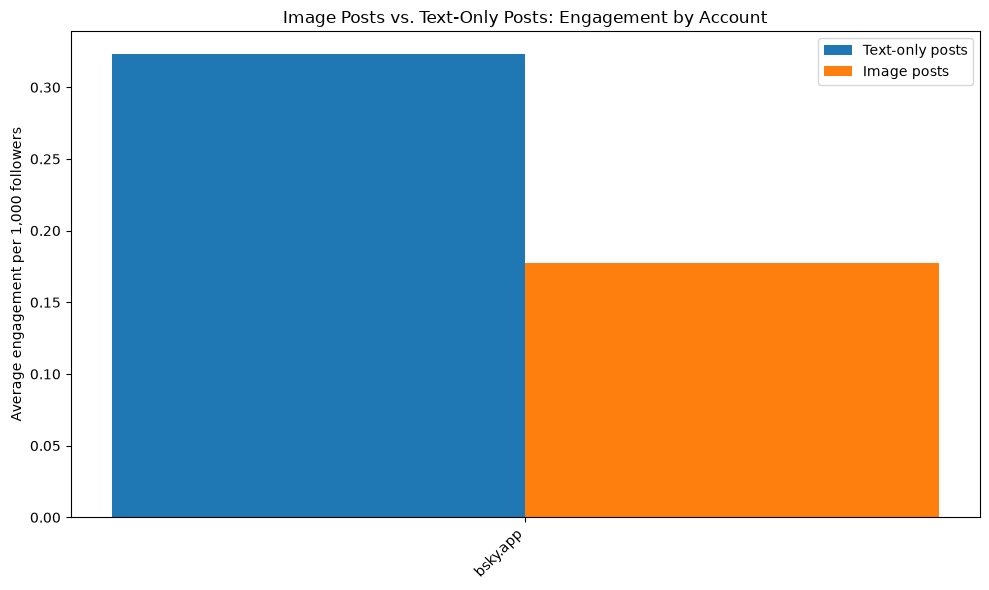

In [15]:
# Account names for the x-axis, and a position number for each one
labels = list(final_df["handle"])
positions = list(range(len(labels)))
bar_width = 0.4

# Create the chart
fig, ax = plt.subplots(figsize=(10, 6))

# Draw two bars per account: text bars shifted left, image bars shifted right
ax.bar([p - bar_width / 2 for p in positions], final_df["text_per_1k"],
       width=bar_width, label="Text-only posts")
ax.bar([p + bar_width / 2 for p in positions], final_df["image_per_1k"],
       width=bar_width, label="Image posts")

# Put the account names under the bars, tilted so they don't overlap
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=45, ha="right")

# Add axis labels, a title, and a legend explaining the colors
ax.set_ylabel("Average engagement per 1,000 followers")
ax.set_title("Image Posts vs. Text-Only Posts: Engagement by Account")
ax.legend()
plt.tight_layout()
plt.show()

The scatter plot gives a second view of the same comparison. Each dot is one account, with its average text-only engagement on the x-axis and its average image engagement on the y-axis. The dashed line marks where the two are equal: dots above the line are accounts where image posts did better, and dots below it are accounts where text-only posts did better. With only bsky.app in the final dataset, the chart has a single dot. It falls below the line, meaning text-only posts received more engagement than image posts for this account.

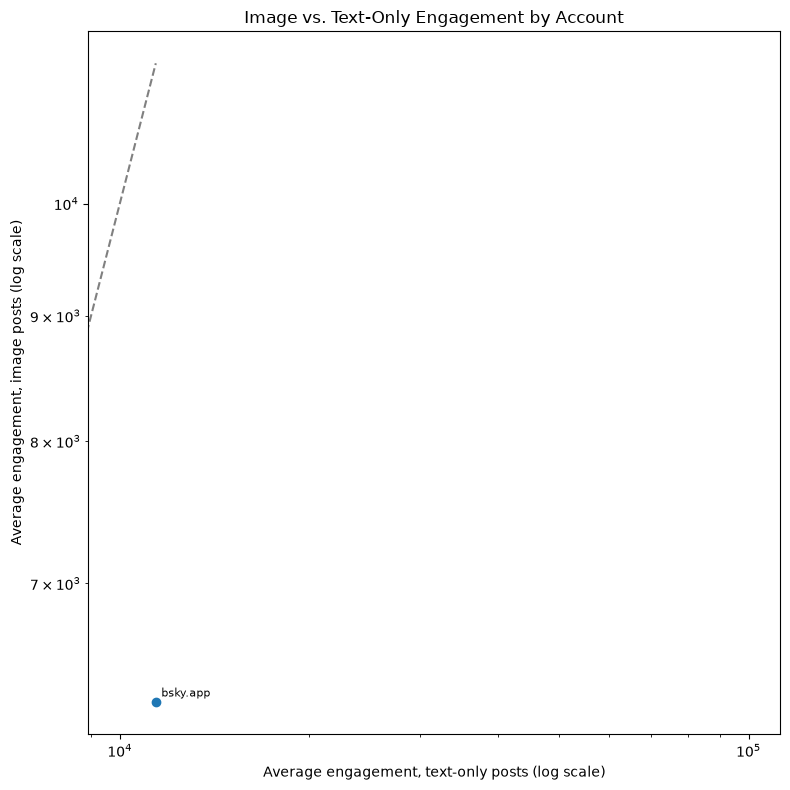

In [16]:
# Create the chart, with one dot per account:
# x = average text-only engagement, y = average image engagement
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(final_df["avg_engagement_text"], final_df["avg_engagement_image"])

# Label each dot with the account handle
for _, row in final_df.iterrows():
    ax.annotate(row["handle"], (row["avg_engagement_text"], row["avg_engagement_image"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")

# Dashed line where image engagement equals text engagement
# Dots above the line = image posts did better
max_value = max(final_df["avg_engagement_text"].max(), final_df["avg_engagement_image"].max())
ax.plot([0, max_value], [0, max_value], linestyle="--", color="gray")


ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Average engagement, text-only posts (log scale)")
ax.set_ylabel("Average engagement, image posts (log scale)")
ax.set_title("Image vs. Text-Only Engagement by Account")
plt.tight_layout()
plt.show()

Two summary numbers help describe the overall pattern: how many accounts had higher average engagement on image posts, and the typical (median) engagement for each post type. I report the median because a few viral posts can pull the average far upward.

In [17]:
# Count the accounts where image posts did better (ratio above 1)
image_wins = (final_df["image_to_text_ratio"] > 1).sum()
print("Accounts where image posts averaged more engagement:", image_wins, "out of", len(final_df))
print()

# The middle (median) engagement for each post type across all posts.
# The median isn't pulled up by a few viral posts the way an average is
print("Median engagement per post, all accounts combined:")
print(combined_df.groupby("post_type")["engagement"].median())

Accounts where image posts averaged more engagement: 0 out of 1

Median engagement per post, all accounts combined:
post_type
image        665.0
text_only    261.0
Name: engagement, dtype: float64


## Conclusions

These results do not support my hypothesis, but the evidence is very limited.

Only one account, bsky.app, had at least five image posts and five text-only posts. For that account, image posts averaged about 6,257 engagements, compared with about 11,413 for text-only posts, so image posts earned only about 55% as much. This is the opposite of what the hypothesis predicted. However, a single account cannot tell us how Bluesky works in general, and bsky.app is unusual: it is the platform's official account, and its text-only posts are often major announcements that would draw attention regardless of format.

The most important finding is about the sample itself. Seven of the eight accounts did not have enough of both post types to compare:

- jay.bsky.team had only 3 text-only posts, pfrazee.com had only 1 image post, and georgetakei.bsky.social had only 1 of each.
- theonion.com, nytimes.com, and washingtonpost.com posted images but no text-only posts.
- npr.org had no image or text-only posts at all.

Most posts in the sample (452 of 634) used other formats, such as link cards, videos, and quote posts. This suggests that large accounts, especially news organizations, rarely post plain images or plain text on Bluesky, which makes a within-account comparison difficult with only 100 posts per account.

The pooled numbers show why the within-account design matters. Across all accounts combined, the median image post received 740 engagements, compared with 230 for text-only posts, which seems to support the hypothesis. But this comparison mixes different accounts. The Onion alone contributed 67 image posts and no text-only posts, so the pooled median mostly reflects *which accounts* post images, not whether images help a given account. When the comparison is made within the same account, the pattern reverses.

## Limitations, Alternative Approaches, and Next Steps

**Limitations of the data and analysis**
- The sample is small and hand-picked, so it represents well-known accounts rather than typical Bluesky users.
- Engagement counts are snapshots. Recent posts had less time to collect engagement than older ones.
- Without view counts, dividing by followers is only an approximation of reach.
- Accounts may use images selectively, for example, only for major announcements, which would make images look more effective than they are.
- Each account's posts cover a different time window, so accounts weren't observed under the same conditions.
- Only one account met the minimum of five posts of each type, so the within-account result rests on 27 posts from a single, unusual account.
- Most posts (452 of 634) were excluded as "other." Quote posts that include images (`app.bsky.embed.recordWithMedia#view`) were also counted as "other," so some posts with images were left out.
- Pinned posts were removed along with reposts, because both have a reason field.

**Alternative approaches**
- Use app.bsky.feed.searchPosts to collect posts on a single topic, which would control for subject matter, if the endpoint is available.
- Only include posts at least 48 hours old so every post has had a similar amount of time to collect engagement.
- Add video and link-card posts as additional categories to compare a fuller range of post types.

**Next steps**
- Expand the sample to more accounts, ideally chosen from a defined list (such as a Bluesky starter pack) rather than by hand.
- Collect more than 100 posts per account using the cursor value that getAuthorFeed returns, which points to the next page of results.